In [1]:
#pip install matplotlib

In [2]:
pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------------------
# 0. ตั้งค่า path และโหลดข้อมูล
# ---------------------------------------------------------------------------
# โฟลเดอร์หลักของโครงงาน (แก้ให้ตรงกับเครื่องของคุณ)
ROOT = Path("C:/Users/suepp/Desktop/IT_Salary_Analysis")

DATA = ROOT / "data" / "processed" / "salary_clean.csv"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA)
print(f"โหลดข้อมูล {len(df)} แถว {df.shape[1]} คอลัมน์")
print(f"เงินเดือนต่ำสุด-สูงสุด: {df['salary_eur'].min():,.0f} - {df['salary_eur'].max():,.0f} EUR")

# จัดกลุ่มเมืองไว้ใช้ในการวิเคราะห์ (สร้างในโน้ตบุ๊กนี้ ไม่ได้เก็บในไฟล์ข้อมูล)
TOP_CITIES = ["Berlin", "Munich", "Frankfurt", "Hamburg", "Stuttgart"]
df["city_group"] = df["city"].where(df["city"].isin(TOP_CITIES), "Other")

# เรียงลำดับหมวดหมู่ให้อ่านง่าย (ชื่อเป็นอังกฤษตามข้อมูล)
ORDER_SEN = ["Junior", "Middle", "Senior", "Lead", "Head"]
ORDER_SIZE = ["up to 10", "11-50", "51-100", "101-1000", "1000+"]
ORDER_CITY = ["Berlin", "Munich", "Frankfurt", "Hamburg", "Stuttgart", "Other"]

# เทคโนโลยีหลัก: รวมตัวสะกดต่างกัน เช่น 'Python' กับ 'python' ให้เป็นค่าเดียว
key = df["main_tech"].str.strip().str.lower()
canon = df.groupby(key)["main_tech"].agg(lambda s: s.value_counts().index[0])
df["main_tech_std"] = key.map(canon)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
BLUE, ORANGE = "#2f6db5", "#e07b39"

def save(name):
    """บันทึกกราฟลง results/figures แล้วแสดงในโน้ตบุ๊ก"""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()
    print("บันทึกกราฟ:", name)

โหลดข้อมูล 1182 แถว 19 คอลัมน์
เงินเดือนต่ำสุด-สูงสุด: 10,001 - 300,000 EUR


## 1. สถิติพื้นฐาน

In [4]:
# 1.1 ตัวแปรเชิงปริมาณ: จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ควอไทล์
num_cols = ["salary_eur", "bonus_eur", "salary_prev_year_eur", "age",
            "exp_total_years", "exp_germany_years", "vacation_days"]
desc = df[num_cols].describe().T
desc["missing"] = df[num_cols].isna().sum()
desc = desc.round(1)
desc.to_csv(TAB / "descriptive_numeric.csv")
print("สถิติเชิงพรรณนา")
display(desc)

# 1.2 ตัวแปรเชิงกลุ่ม: ความถี่และร้อยละ
cat_cols = ["gender", "seniority", "city_group", "company_size",
            "company_type", "employment_status", "work_language"]
freq = []
for c in cat_cols:
    t = df[c].value_counts(dropna=False).rename_axis("category").reset_index(name="n")
    t["percent"] = (t["n"] / len(df) * 100).round(1)
    t.insert(0, "variable", c)
    freq.append(t)
freq = pd.concat(freq, ignore_index=True)
freq.to_csv(TAB / "frequency_categorical.csv", index=False)
print("ความถี่ของตัวแปรเชิงกลุ่ม")
display(freq)

สถิติเชิงพรรณนา


,count,mean,std,min,25%,50%,75%,max,missing
salary_eur,1182.0,71043.7,24337.8,10001.0,58850.0,70000.0,80000.0,300000.0,0
bonus_eur,787.0,20287.6,36314.6,0.0,0.0,5000.0,20000.0,450000.0,395
salary_prev_year_eur,851.0,66707.9,21329.9,11000.0,55000.0,65000.0,75000.0,230000.0,331
age,1182.0,32.4,5.5,20.0,29.0,32.0,35.0,66.0,0
exp_total_years,1182.0,8.8,5.3,0.0,5.0,8.0,12.0,40.0,0
exp_germany_years,1138.0,3.7,3.5,0.0,1.0,3.0,5.0,30.0,44
vacation_days,1117.0,28.0,3.8,0.0,27.0,28.0,30.0,60.0,65


ความถี่ของตัวแปรเชิงกลุ่ม


,variable,category,n,percent
0,gender,Male,996,84.3
1,gender,Female,181,15.3
2,gender,NaN,3,0.3
3,gender,Diverse,2,0.2
4,seniority,Senior,542,45.9
5,seniority,Middle,350,29.6
6,seniority,Lead,157,13.3
7,seniority,Junior,75,6.3
8,seniority,Head,39,3.3
9,seniority,Other,19,1.6


In [5]:
# 1.3 เงินเดือนแยกตามกลุ่ม: n, ค่าเฉลี่ย, มัธยฐาน, SD, Q1, Q3
def salary_by(col, order=None):
    g = df.groupby(col)["salary_eur"]
    out = pd.DataFrame({
        "n": g.size(), "mean": g.mean(), "median": g.median(), "sd": g.std(),
        "q1": g.quantile(0.25), "q3": g.quantile(0.75)}).round(0)
    if order:
        out = out.reindex([o for o in order if o in out.index])
    return out

group_tables = {
    "seniority": salary_by("seniority", ORDER_SEN),
    "city_group": salary_by("city_group", ORDER_CITY),
    "company_size": salary_by("company_size", ORDER_SIZE),
    "company_type": salary_by("company_type"),
}
for name, t in group_tables.items():
    t.to_csv(TAB / f"salary_by_{name}.csv")
    print(f"เงินเดือนตาม {name}")
    display(t)

เงินเดือนตาม seniority


,n,mean,median,sd,q1,q3
seniority,,,,,,
Junior,75,50233.0,48000.0,32013.0,42500.0,55000.0
Middle,350,58850.0,60000.0,14971.0,52000.0,65900.0
Senior,542,74078.0,72000.0,17857.0,65000.0,80000.0
Lead,157,88904.0,85000.0,26124.0,76000.0,95500.0
Head,39,102013.0,93000.0,31691.0,84500.0,110000.0


เงินเดือนตาม city_group


,n,mean,median,sd,q1,q3
city_group,,,,,,
Berlin,641,72642.0,70000.0,21325.0,60000.0,80000.0
Munich,227,78413.0,73500.0,26286.0,65000.0,84500.0
Frankfurt,42,66331.0,65000.0,19786.0,52125.0,74500.0
Hamburg,36,63143.0,64000.0,21655.0,50000.0,76250.0
Stuttgart,30,68350.0,66100.0,14783.0,58500.0,75750.0
Other,206,60682.0,57880.0,29138.0,45000.0,72000.0


เงินเดือนตาม company_size


,n,mean,median,sd,q1,q3
company_size,,,,,,
up to 10,57,65229.0,56000.0,40588.0,43000.0,70000.0
51-100,141,64913.0,65000.0,18858.0,55000.0,75000.0
101-1000,384,70952.0,70000.0,20978.0,60000.0,78000.0
1000+,426,76356.0,74000.0,24766.0,62550.0,85000.0


เงินเดือนตาม company_type


,n,mean,median,sd,q1,q3
company_type,,,,,,
Consulting / Agency,133,65310.0,60000.0,26943.0,52500.0,70800.0
Other,71,70477.0,68000.0,28657.0,54000.0,80000.0
Product,720,72392.0,70000.0,21957.0,60000.0,80000.0
Startup,243,71270.0,70000.0,27584.0,58000.0,80000.0


## 2. กราฟสำรวจข้อมูล

C:\Users\suepp\AppData\Local\Temp\ipykernel_35232\3978502555.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axb.boxplot(s, vert=False, patch_artist=True, widths=0.6,
C:\Users\suepp\AppData\Local\Temp\ipykernel_35232\1794677622.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


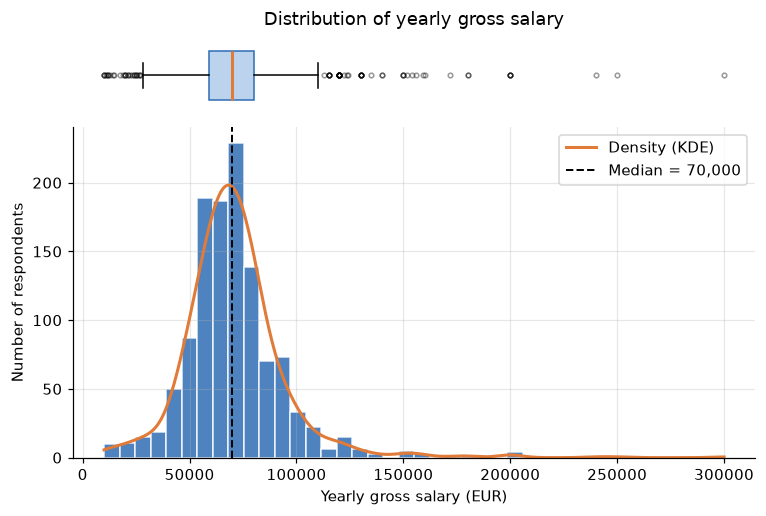

บันทึกกราฟ: fig01_salary_histogram.png


In [6]:
# กราฟที่ 1: การกระจายของเงินเดือน (ฮิสโตแกรม + เส้น KDE + boxplot ด้านบน)
from scipy.stats import gaussian_kde

s = df["salary_eur"].dropna()
med = s.median()
fig, (axb, axh) = plt.subplots(2, 1, figsize=(8, 5), sharex=True,
                               gridspec_kw={"height_ratios": [1, 4], "hspace": 0.05})
axh.hist(s, bins=40, color=BLUE, edgecolor="white", alpha=0.85)
xs = np.linspace(s.min(), s.max(), 400)
binw = (s.max() - s.min()) / 40
axh.plot(xs, gaussian_kde(s)(xs) * len(s) * binw, color=ORANGE, lw=2, label="Density (KDE)")
axh.axvline(med, color="black", ls="--", lw=1.3, label=f"Median = {med:,.0f}")
axh.set_xlabel("Yearly gross salary (EUR)"); axh.set_ylabel("Number of respondents")
axh.legend()
axb.boxplot(s, vert=False, patch_artist=True, widths=0.6,
            boxprops={"facecolor": "#bcd3ee", "edgecolor": BLUE},
            medianprops={"color": ORANGE, "lw": 2},
            flierprops={"markersize": 3, "alpha": 0.4})
axb.set_yticks([]); axb.grid(False)
axb.spines["left"].set_visible(False); axb.spines["bottom"].set_visible(False)
axb.tick_params(axis="x", length=0)
axb.set_title("Distribution of yearly gross salary")
save("fig01_salary_histogram.png")


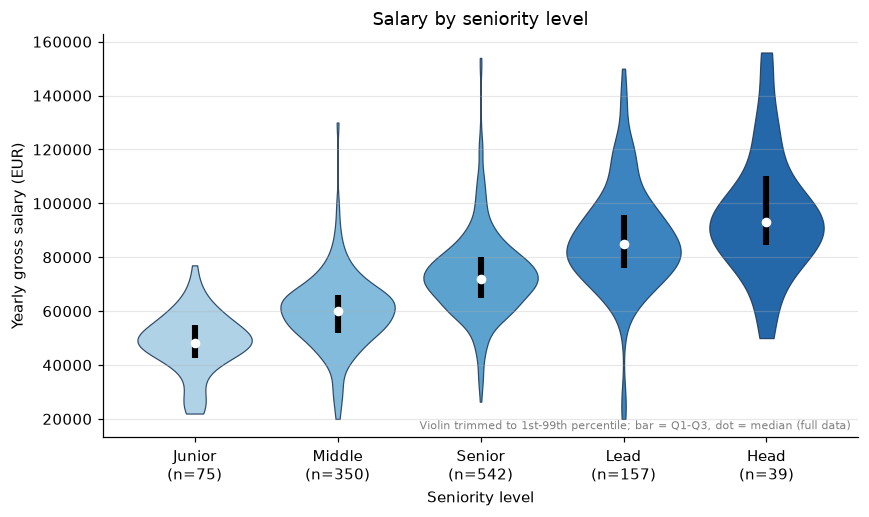

บันทึกกราฟ: fig02_salary_by_seniority.png


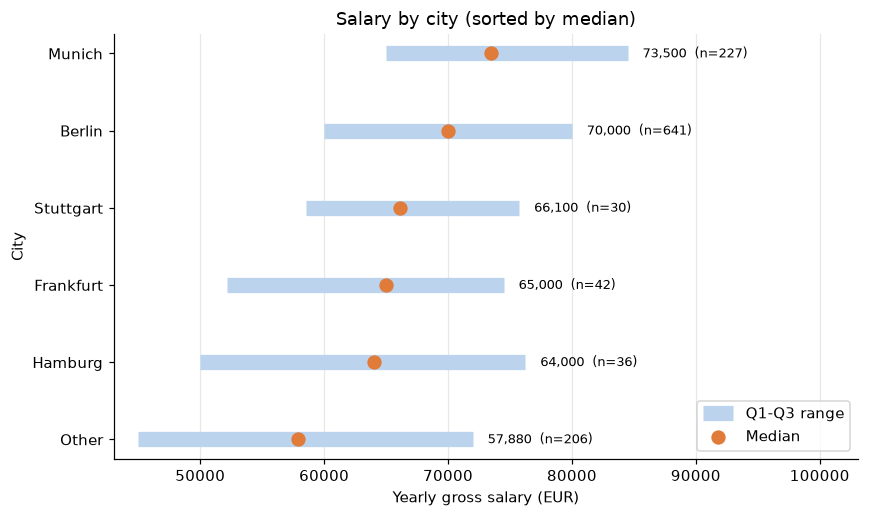

บันทึกกราฟ: fig03_salary_by_city.png


In [7]:
# กราฟที่ 2: เงินเดือนตามระดับ Seniority (violin plot + มัธยฐานและช่วง Q1-Q3)
cats = [c for c in ORDER_SEN if c in df["seniority"].dropna().unique()]
data = [df.loc[df["seniority"] == c, "salary_eur"].dropna().values for c in cats]
lo, hi = df["salary_eur"].quantile([0.01, 0.99])        # ตัดหางสุดขั้วเฉพาะการวาดรูป violin
data_v = [d[(d >= lo) & (d <= hi)] for d in data]
colors = plt.cm.Blues(np.linspace(0.35, 0.85, len(cats)))

fig, ax = plt.subplots(figsize=(8, 4.8))
parts = ax.violinplot(data_v, positions=range(len(cats)), widths=0.8,
                      showextrema=False)
for body, col in zip(parts["bodies"], colors):
    body.set(facecolor=col, edgecolor="#1f3b5c", lw=0.8, alpha=0.9)
for i, d in enumerate(data):
    q1, m, q3 = np.percentile(d, [25, 50, 75])
    ax.vlines(i, q1, q3, color="black", lw=4, zorder=3)          # ช่วง Q1-Q3
    ax.scatter(i, m, color="white", s=28, zorder=4)              # มัธยฐาน
ax.set_xticks(range(len(cats)))
ax.set_xticklabels([f"{c}\n(n={len(d)})" for c, d in zip(cats, data)])
ax.set_xlabel("Seniority level"); ax.set_ylabel("Yearly gross salary (EUR)")
ax.set_title("Salary by seniority level")
ax.grid(axis="x", visible=False)
ax.text(0.99, 0.02, "Violin trimmed to 1st-99th percentile; bar = Q1-Q3, dot = median (full data)",
        transform=ax.transAxes, ha="right", fontsize=7.5, color="gray")
save("fig02_salary_by_seniority.png")

# กราฟที่ 3: เงินเดือนตามเมือง (range plot แนวนอน: Q1-Q3 + มัธยฐาน เรียงตามมัธยฐาน)
g = df.groupby("city_group")["salary_eur"]
tab = pd.DataFrame({"n": g.size(), "q1": g.quantile(0.25),
                    "med": g.median(), "q3": g.quantile(0.75)})
tab = tab.sort_values("med")
y = np.arange(len(tab))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hlines(y, tab["q1"], tab["q3"], color="#bcd3ee", lw=10, label="Q1-Q3 range")
ax.scatter(tab["med"], y, color=ORANGE, s=70, zorder=3, label="Median")
for yi, (_, r) in zip(y, tab.iterrows()):
    ax.text(r["q3"] + 1200, yi, f"{r['med']:,.0f}  (n={int(r['n'])})",
            va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(tab.index)
ax.set_xlim(right=tab["q3"].max() * 1.22)
ax.set_xlabel("Yearly gross salary (EUR)"); ax.set_ylabel("City")
ax.set_title("Salary by city (sorted by median)")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
save("fig03_salary_by_city.png")


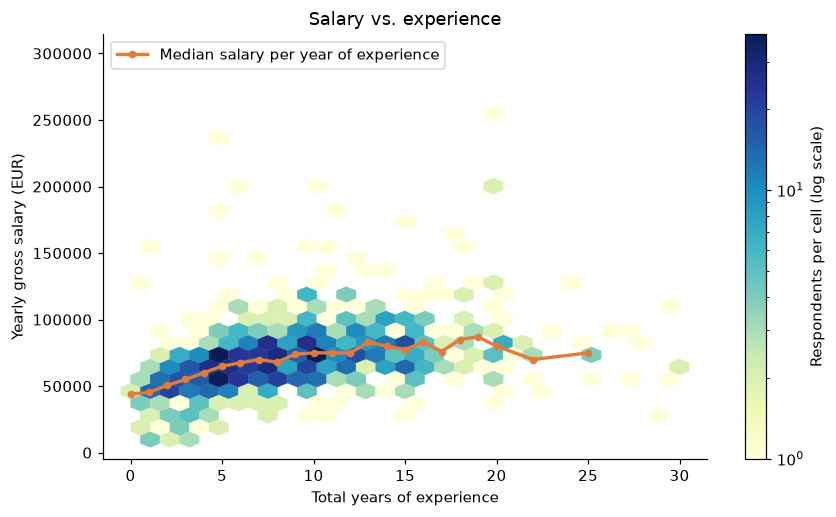

บันทึกกราฟ: fig04_salary_vs_experience.png


In [8]:
# กราฟที่ 4: ประสบการณ์รวมกับเงินเดือน (hexbin แสดงความหนาแน่น + มัธยฐานรายปี)
d = df[["exp_total_years", "salary_eur"]].dropna()
d = d[d["exp_total_years"] <= 30]          # แสดงเฉพาะประสบการณ์ไม่เกิน 30 ปี เพื่อให้กราฟอ่านง่าย

fig, ax = plt.subplots(figsize=(8, 4.8))
hb = ax.hexbin(d["exp_total_years"], d["salary_eur"], gridsize=28, cmap="YlGnBu",
               mincnt=1, bins="log", linewidths=0.2)
fig.colorbar(hb, ax=ax, label="Respondents per cell (log scale)")

# มัธยฐานรายปีของประสบการณ์ (เฉพาะปีที่มีผู้ตอบ >= 5 คน)
yr = d.assign(yr=d["exp_total_years"].round()).groupby("yr")["salary_eur"]
yr = pd.DataFrame({"med": yr.median(), "n": yr.size()}).query("n >= 5")
ax.plot(yr.index, yr["med"], color=ORANGE, lw=2.2, marker="o", ms=4,
        label="Median salary per year of experience")
ax.set_xlabel("Total years of experience"); ax.set_ylabel("Yearly gross salary (EUR)")
ax.set_title("Salary vs. experience"); ax.legend(loc="upper left")
ax.grid(False)
save("fig04_salary_vs_experience.png")


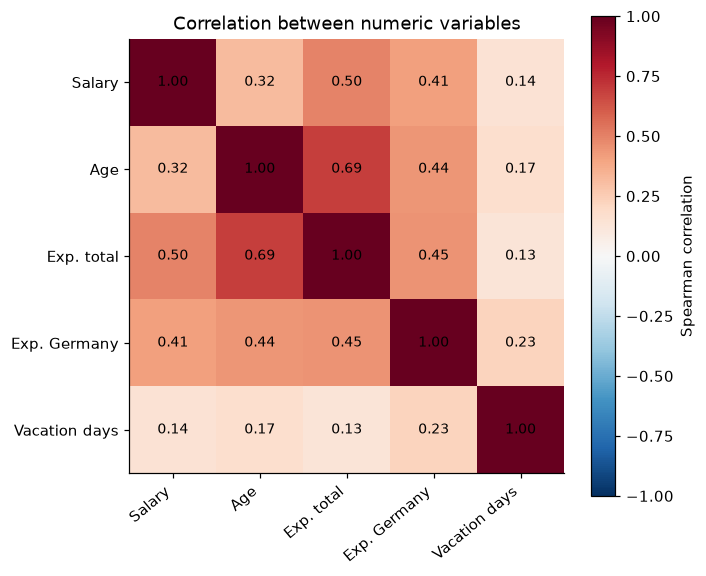

บันทึกกราฟ: fig05_correlation_heatmap.png


In [9]:
# กราฟที่ 5: heatmap สหสัมพันธ์ Spearman (เหมาะกับเงินเดือนที่การกระจายเบ้)
corr_cols = ["salary_eur", "age", "exp_total_years", "exp_germany_years", "vacation_days"]
labels = ["Salary", "Age", "Exp. total", "Exp. Germany", "Vacation days"]
corr = df[corr_cols].corr(method="spearman")
corr.round(2).to_csv(TAB / "correlation_spearman.csv")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Correlation between numeric variables")
save("fig05_correlation_heatmap.png")

## 3. โมเดล Random Forest พยากรณ์เงินเดือน

**เป้าหมาย:** พยากรณ์ `salary_eur` (เงินเดือนรวมต่อปี ยูโร) จากข้อมูลของผู้ตอบ

**ตัวแปรที่ใช้:** อายุ, ประสบการณ์รวม, ประสบการณ์ในเยอรมนี, วันลา, ระดับ Seniority, เมือง (จัดกลุ่ม), ขนาดบริษัท, ประเภทบริษัท, ประเภทสัญญา, ภาษาที่ใช้ทำงาน, เทคโนโลยีหลัก

**ที่ไม่ใช้โดยตั้งใจ:**
- `bonus_eur`, `salary_prev_year_eur`, `bonus_prev_year_eur` — เป็นตัวเลขรายได้ที่ใกล้เคียงกับค่าที่จะพยากรณ์มาก ถ้าใส่เข้าไปโมเดลจะ "ลอกคำตอบ" ไม่ได้บอกอะไรเชิงโครงสร้าง
- `gender` — ไม่นำคุณลักษณะส่วนบุคคลที่อ่อนไหวมาเป็นตัวพยากรณ์รายได้
- `position`, `other_tech` — ข้อความอิสระ มีค่าต่างกันมากเกินไป

**วิธีประเมิน:** แบ่งข้อมูล 80% ฝึกโมเดล และ 20% ทดสอบ (`random_state=42`) เลือกพารามิเตอร์ด้วย GridSearchCV 5-fold จากชุดฝึกเท่านั้น แล้วเทียบกับโมเดลพื้นฐานที่ทายด้วยมัธยฐานเสมอ

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# ตัวแปรตัวเลขที่ใช้พยากรณ์
NUM = ["age", "exp_total_years", "exp_germany_years", "vacation_days"]

X = df[NUM]
y = df["salary_eur"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"ชุดฝึก {len(X_train)} แถว | ชุดทดสอบ {len(X_test)} แถว")

# โมเดล Random Forest: เติมค่าว่างด้วยมัธยฐาน แล้วฝึกโมเดล
best = Pipeline([("imp", SimpleImputer(strategy="median")),
                 ("model", RandomForestRegressor(n_estimators=300, max_depth=12,
                                                 max_features="sqrt", min_samples_leaf=1,
                                                 random_state=42, n_jobs=-1))])
best.fit(X_train, y_train)

def metrics(X_, y_, name):
    p = best.predict(X_)
    return {"dataset": name, "n": len(y_),
            "MAE (EUR)": mean_absolute_error(y_, p),
            "RMSE (EUR)": np.sqrt(mean_squared_error(y_, p)),
            "R2": r2_score(y_, p)}

res = pd.DataFrame([metrics(X_train, y_train, "Train"),
                    metrics(X_test, y_test, "Test")]).round(2)
res.to_csv(TAB / "model_metrics.csv", index=False)
print("บันทึกตาราง: model_metrics.csv")
print("\nผลของ Random Forest (หน่วยเงิน = EUR)")
display(res)

ชุดฝึก 945 แถว | ชุดทดสอบ 237 แถว
บันทึกตาราง: model_metrics.csv

ผลของ Random Forest (หน่วยเงิน = EUR)


,dataset,n,MAE (EUR),RMSE (EUR),R2
0,Train,945,8407.43,11475.70,0.76
1,Test,237,14095.35,26325.87,0.13


In [11]:
# ตัวอย่างการพยากรณ์ (ข้อมูลสมมติ ไม่ใช่ข้อมูลของบุคคลจริง)
example = pd.DataFrame([{
    "age": 32, "exp_total_years": 8, "exp_germany_years": 5, "vacation_days": 28}])
est = best.predict(example)[0]
mae = mean_absolute_error(y_test, best.predict(X_test))
print(f"ตัวอย่างสมมติ (อายุ 32 ปี, ประสบการณ์รวม 8 ปี): พยากรณ์ประมาณ {est:,.0f} EUR/ปี")
print(f"ความคลาดเคลื่อนโดยทั่วไปของโมเดล (MAE) ≈ {mae:,.0f} EUR จึงควรมองเป็นช่วง ไม่ใช่ตัวเลขเดียว")

ตัวอย่างสมมติ (อายุ 32 ปี, ประสบการณ์รวม 8 ปี): พยากรณ์ประมาณ 76,834 EUR/ปี
ความคลาดเคลื่อนโดยทั่วไปของโมเดล (MAE) ≈ 14,095 EUR จึงควรมองเป็นช่วง ไม่ใช่ตัวเลขเดียว


In [12]:
# เวอร์ชันของโปรแกรมที่ใช้ (ใส่ใน README และ requirements.txt)
import sys, sklearn
print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", plt.matplotlib.__version__, "| scikit-learn", sklearn.__version__)

Python 3.15.0
pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | scikit-learn 1.9.1
